In [226]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.wong import sigma
import scienceplots
plt.style.use(['science', 'no-latex', 'ieee'])

import scipy as sp
import os
from scipy.optimize import curve_fit
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern, ConstantKernel, ExpSineSquared, RationalQuadratic
import findiff as fd

#plt.rc('xtick', labelsize=14)
#plt.rc('ytick', labelsize=14)
#plt.rc('legend', fontsize=10)  
plt.rc('axes', labelsize=14) 
plt.rcParams['axes.titlesize'] = 20
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
plt.rc('legend', fontsize=10)  
#plt.rc('lines', linewidth=2)  # all future legends will be 14-pt

Best-fit parameters:
  E0    = 73.3846 ± 0.0047 MeV
  R0    = 10.2260 ± 0.0078 fm
  hbarw = 4.8410 ± 0.0074 MeV


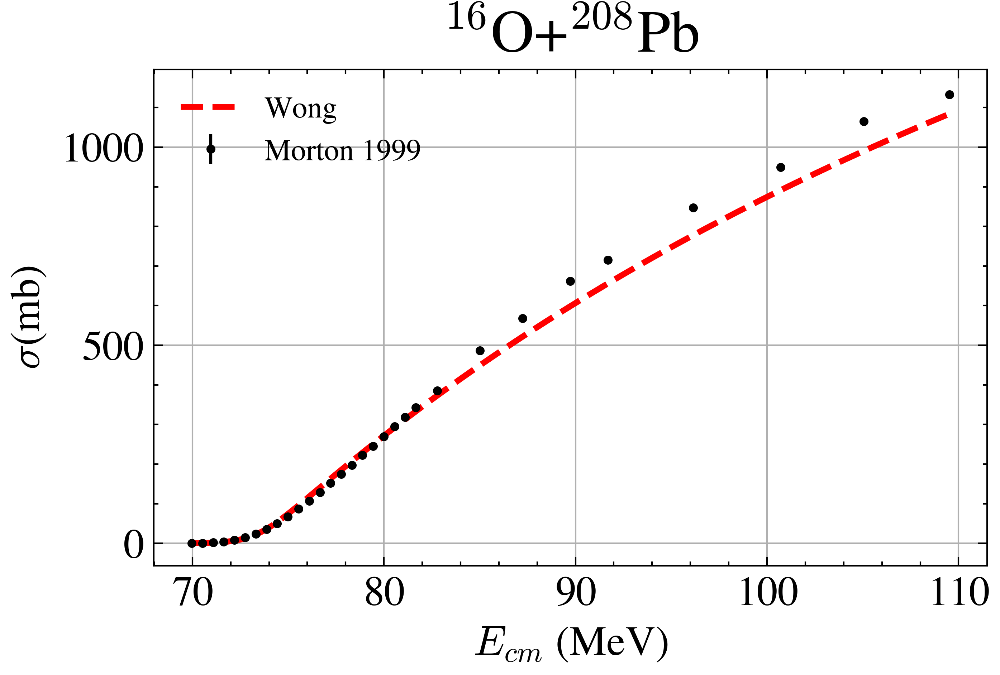

In [230]:
dirname = "/Users/aaronphilip/Senior Thesis/barrier-distribution-sample/16O208Pb_exp"
system = "$^{208}$Pb+$^{16}$O"
fileprefix = dirname

expfiles = [ 'expMort.dat', 'expDas.dat' ]
explabel = [ 'Morton et al. 1999', 'Dasgupta et al. 2007' ]
expmarker = [ 'o', 's' ]
expcolor = [ 'k', 'g' ]

exp = []

for file in expfiles:
    tmpdf = pd.read_csv(os.path.join(dirname,file),sep='\s+',names=['Ecm','Sigma','Error'])
    if(tmpdf['Ecm'].iloc[0] > tmpdf['Ecm'].iloc[-1]):
        exp.append(tmpdf.iloc[::-1])
    else:
        exp.append(tmpdf)

xmin = 70.0
xmax = 90.0


E_data = exp[0]['Ecm'].to_numpy()
Sigma_data = exp[0]['Sigma'].to_numpy()
Sigma_err  = exp[0]['Error'].to_numpy()


# --- Initial guesses for [E0, R0, hbarw] ---
# You may need to tweak these based on your system.
initial_guess = [70.0, 11.0, 4]  # e.g. E0≈10MeV, R0≈7fm, ħω≈4MeV

# --- Perform the fit ---
popt, pcov = curve_fit(
    sigma,
    E_data,
    Sigma_data,
    p0=initial_guess,
    sigma=Sigma_err,
    absolute_sigma=True,
    # bounds can help keep parameters physical:
    bounds=([0.0, 8.0, 0.0], [np.inf, 15.0, np.inf])
)

E0_opt, R0_opt, hbarw_opt = popt
perr = np.sqrt(np.diag(pcov))

print(f"Best-fit parameters:")
print(f"  E0    = {E0_opt:.4f} ± {perr[0]:.4f} MeV")
print(f"  R0    = {R0_opt:.4f} ± {perr[1]:.4f} fm")
print(f"  hbarw = {hbarw_opt:.4f} ± {perr[2]:.4f} MeV")

# --- Plot experiment vs. fit ---
E_plot = np.linspace(E_data.min(), E_data.max(), 500)
Sigma_fit = sigma(E_plot, E0_opt, R0_opt, hbarw_opt)

plt.figure(figsize=(5,3))
plt.errorbar(E_data, Sigma_data, yerr=Sigma_err, fmt='o', label='Morton 1999', markersize=2)
#plt.scatter(E_data, Sigma_data, label='Morton 1999', color='k', s=10)
plt.plot(E_plot, Sigma_fit, label='Wong', linewidth=2)
plt.xlabel(r'$E_{cm}$ (MeV)')
plt.ylabel(r'$\sigma$(mb)')
plt.title("$^{16}$O+$^{208}$Pb")
plt.legend()
plt.grid(True)
#plt.tight_layout()
plt.show()

In [220]:
N = 1000
total_E = np.concatenate((exp[0]['Ecm'].to_numpy(), exp[1]['Ecm'].to_numpy()))
E_fine = np.linspace(total_E.min(), total_E.max(), N)

# Number of Monte‐Carlo draws to propagate parameter‐uncertainty:
M = 200 

# Covariance of (E0,R0,hbarw) from your fit:
P_cov = pcov        # shape (3,3) 

# ┌─────────────────────────────────────────────────────────────────────────────┐
# │  1) Draw M parameter‐samples from  N(popt, pcov)                             │
# └─────────────────────────────────────────────────────────────────────────────┘
# Each row of `param_samples` is (E0_j, R0_j, hbarw_j).
param_samples = np.random.multivariate_normal(
    mean=[E0_opt, R0_opt, hbarw_opt],
    cov=P_cov,
    size=M
)  # shape (M,3)

# ┌─────────────────────────────────────────────────────────────────────────────┐
# │  2) For each of those M sets, compute σ_j(E_data)                            │
# └─────────────────────────────────────────────────────────────────────────────┘
# We'll build a matrix S of shape (M, N) where
#    S[j,i] = σ( E_fine[i];  E0_j, R0_j, hbarw_j ).
S = np.empty((M, N))

for j in range(M):
    E0_j, R0_j, hbarw_j = param_samples[j]
    # Evaluate your analytic sigma‐function on the entire E_fine grid:
    S[j, :] = sigma(E_fine, E0_j, R0_j, hbarw_j)

# ┌─────────────────────────────────────────────────────────────────────────────┐
# │  3) Compute the Monte‐Carlo mean and variance at each E_data[i]               │
# └─────────────────────────────────────────────────────────────────────────────┘
#   mean over j:  shape → (N,)
sigma_mean = S.mean(axis=0)
#   var  over j:  shape → (N,)
sigma_var  = S.var(axis=0, ddof=1)   # unbiased estimate of Var[σ(E_i)]

# If any σ_var[i] happens to be exactly zero (i.e. all S[:,i] identical),
# add a tiny floor so the GP doesn't complain about zero‐noise.
sigma_var += 1e-16

In [221]:
#from src.train import train_gp
from src.plot import plot_gp_with_data
from src.utils import barrier_dist, point_diff

def train_gp(E_train, sigma_mu_train, sigma_var_train, n_restarts=20, kernel=None, noise=None):
    """
    Train a Gaussian Process on 1D data with heteroscedastic noise.

    Parameters
    ----------
    E_train : array-like, shape (N,)
        Training energies.
    sigma_mu_train : array-like, shape (N,)
        Mean cross-section values at E_train.
    delta_sigma_train : array-like, shape (N,)
        Variance of cross-section at E_train (i.e., noise variances).
    n_restarts : int, optional (default=10)
        Number of restarts for the optimizer.

    Returns
    -------
    gp : GaussianProcessRegressor
        The fitted GP model.
    """
    # 1) Sort E_train for length-scale estimation
    E_sorted = np.sort(np.asarray(E_train))
    dE = np.diff(E_sorted)
    ell0 = min(np.abs(dE))
    lbound, ubound = ell0 , 10.0

    # 2) Compute signal variance from the training mean
    var_y0 = np.var(sigma_mu_train)
    print(var_y0)

    if kernel is None:
        # 3) Build kernel: Constant * RBF  + WhiteKernel
        k_rbf   = 1* RBF(length_scale=1.0, length_scale_bounds=(lbound, ubound))#ConstantKernel() length_scale_bounds=(lbound, ubound)) # *ConstantKernel(constant_value=var_y0, constant_value_bounds=(var_y0/100, var_y0*100)) 
        kernel  = k_rbf
        if noise: 
            k_noise = WhiteKernel(noise_level=1e-5 , noise_level_bounds=(1e-9, 1e-3))
            kernel  += k_noise

    # 4) Instantiate and fit GP
    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=sigma_var_train,
        normalize_y=False,
        n_restarts_optimizer=n_restarts
    )
    gp.fit(np.asarray(E_train).reshape(-1, 1), np.asarray(sigma_mu_train))
    return gp

In [222]:
# Create a training set for the GP:
#fine_interval = 10
#coarse_interval = 10
start = 0#np.argmin(np.abs(E_fine - 75.0))
mid = np.argmin(np.abs(E_fine- 80.0))
stop = np.argmin(np.abs(E_fine- 90.0))
E_train = E_fine#np.concatenate((E_fine[start:mid:fine_interval], E_fine[mid:stop:coarse_interval]))
#E_train = E_fine[start:stop:interval]

sigma_train = sigma_mean#np.concatenate((sigma_mean[start:mid:fine_interval], sigma_mean[mid:stop:coarse_interval]))#sigma_mean[start:stop:interval]
sigma_train_var = sigma_var#np.concatenate((sigma_var[start:mid:fine_interval], sigma_var[mid:stop:coarse_interval]))#sigma_var[start:stop:interval]
#gp = train_gp(E_train, sigma_mu_train=sigma_train, sigma_var_train=1e-8)#np.zeros_like(sigma_train_var))


In [224]:
# ┌─ Cell 1: COMPUTATION ──────────────────────────────────────────────────────

# PARAMETERS & GRIDS
noise_ratio = [5e-3, 1e-2, 1e-1, 5e-1]#[1e-16, 1e-8, 1e-4, 1e-2]
E_eval   = np.linspace(E_fine.min() - 10, E_fine.max() + 10, 500)
n_samples = 100

# PRECOMPUTE TRUE D_f(E) ON THE TRAIN GRID
true_d = barrier_dist(
    E_train,
    sigma(E_train, E0_opt, R0_opt, hbarw_opt),
    acc=4
)
# RNG for reproducible corruption
rng = np.random.default_rng(0)

# TRAIN & PREDICT — store in a dict for plotting
results = {}
for i, ratio in enumerate(noise_ratio):
    alpha = (ratio*sigma_train)**2
    sigma_train_noisy = sigma_train+rng.normal(loc=0.0, scale=np.sqrt(alpha))
    gp = train_gp(E_train, sigma_train_noisy, alpha)
    mu, std          = gp.predict(E_eval.reshape(-1, 1), return_std=True)
    samples          = gp.sample_y(E_eval.reshape(-1, 1), n_samples=n_samples)
    results[i] = {
        'gp': gp,
        'mu': mu,
        'std': std,
        'samples': samples,
        'ratio': ratio
    }

132328.51259889427


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


132216.9086696339


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


134582.41532379843


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


234457.22990722512


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


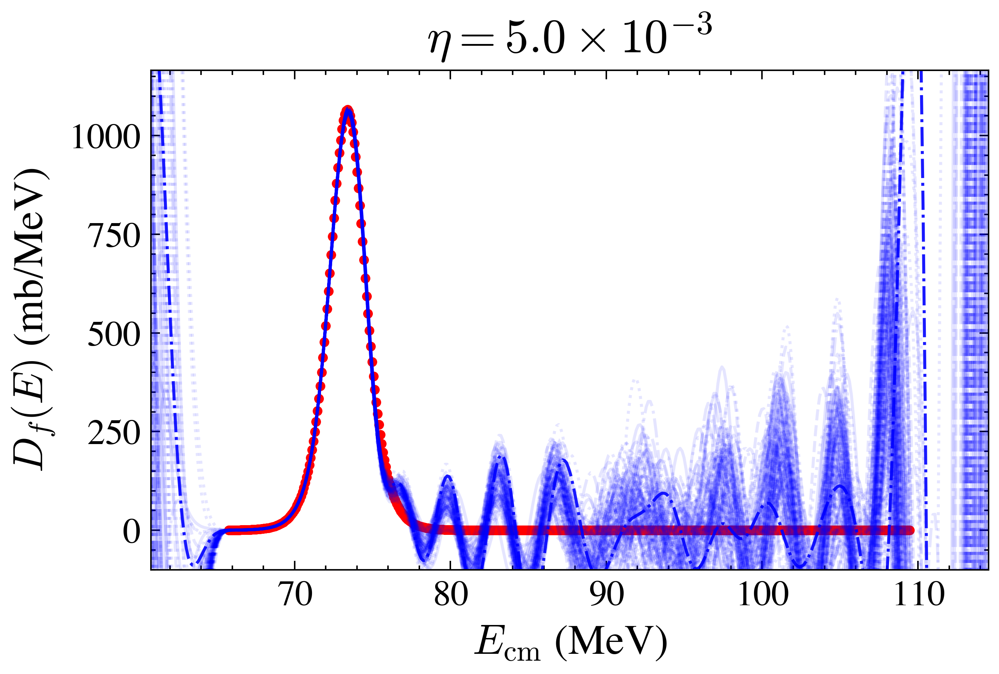

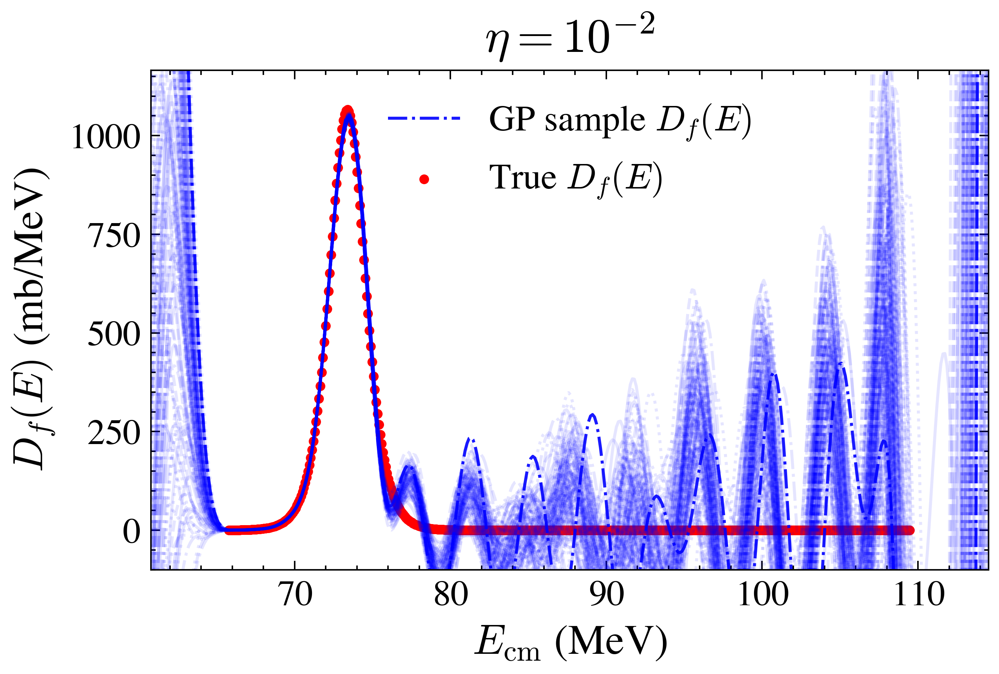

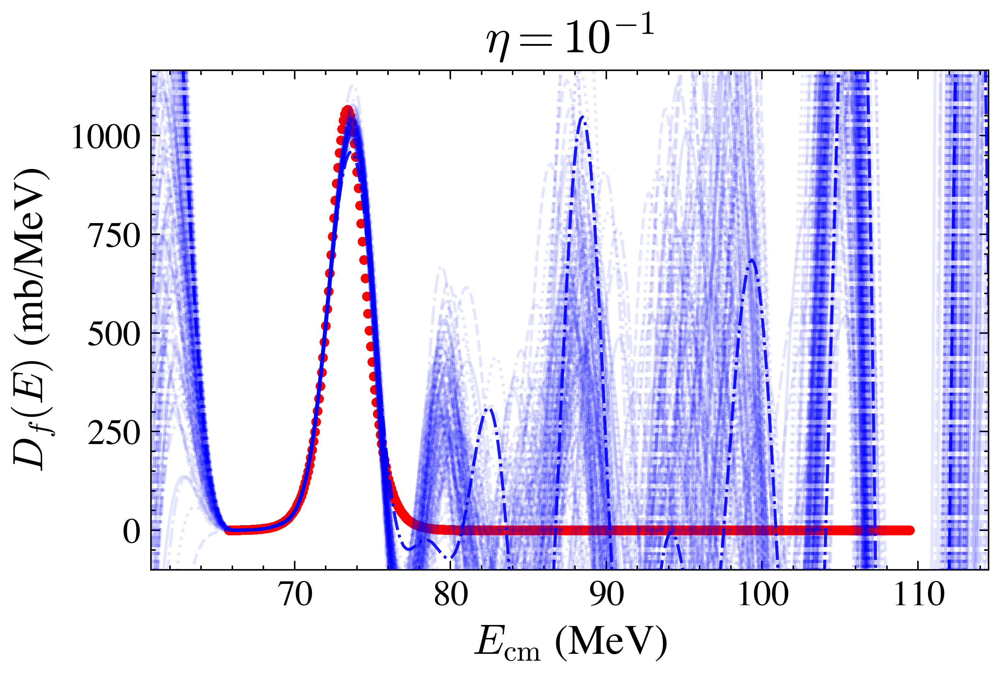

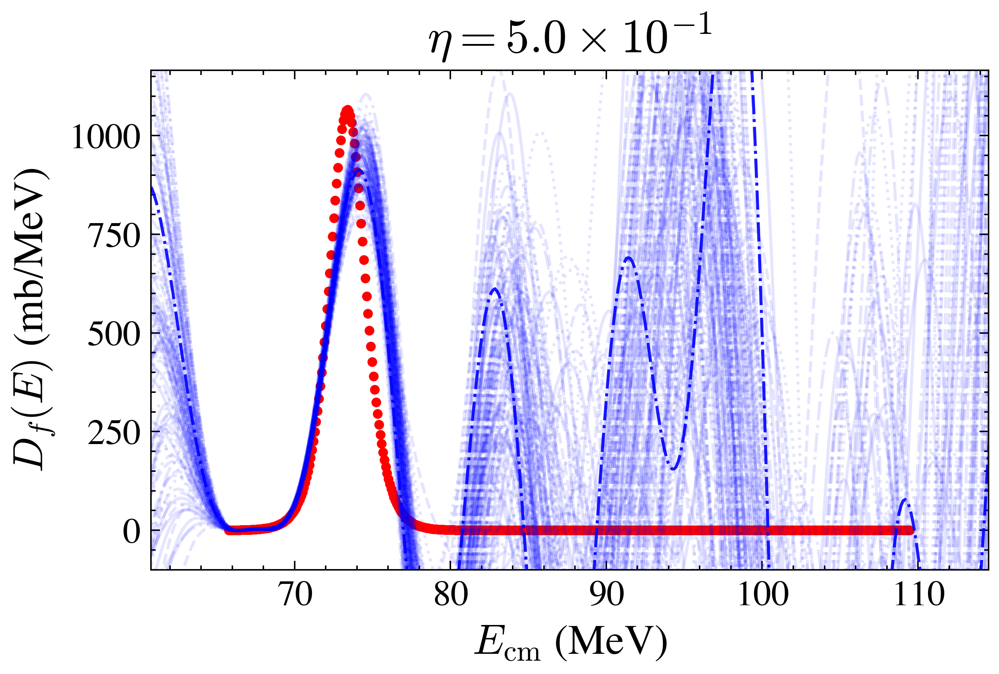

In [ ]:
labeled = False
for i, data in results.items():
    mu      = data['mu']
    std     = data['std']
    samples = data['samples']
    ratio =     data['ratio']
    tag     = f"{i}"
    var = (ratio*sigma_train)**2.0
    
    e = int(np.floor(np.log10(ratio)))
    # 2) get mantissa m so that η = m × 10^e
    m = ratio / 10**e

    # 3) build title
    if np.isclose(m, 1.0):
        # pure power of ten
        title = rf"$\eta = 10^{{{e}}}$"
    else:
        # include mantissa
        title = rf"$\eta = {m:.1f}\times 10^{{{e}}}$"

    # 1) σ(E) fit + 95% CI
    fig, ax = plt.subplots(figsize=(5,3))
    ax.plot(E_eval, mu, lw=2, label="GP mean")
    ax.plot(
        E_eval,
        sigma(E_eval, E0_opt, R0_opt, hbarw_opt),
        linestyle="--", color="C1", label="Wong"
    )
    ax.fill_between(
        E_eval,
        mu - 1.96 * std,
        mu + 1.96 * std,
        alpha=0.3,
        label="95% CI"
    )
    # 1c) scatter the training points (no error-bars), small markers, on top
    ax.scatter(
        E_train,
        sigma_train,
        s=2,               # area in points^2; adjust smaller/larger as you like
        color='red',
        label="Training pts",
        zorder=5
    )
    ax.set_title(title, fontsize=16)
    ax.set_xlabel(r'$E_{\mathrm{cm}}$ (MeV)', fontsize=14)
    ax.set_ylabel(r'$\sigma(E)$', fontsize=14)
    ax.set_xlim(E_eval[0], E_eval[-1])
    if i==1: 
        ax.legend(fontsize=12)
    ax.tick_params(labelsize=12)
    fig.savefig(f'plots/gp_sigma_var_{tag}.png', dpi=300)
    plt.close(fig)

    # 2) Barrier distributions
    fig, ax = plt.subplots(figsize=(5,3))
    for j in range(samples.shape[1]):
        style = dict(alpha=0.1, color='b')
        if j == samples.shape[1] - 1:
            style.update(alpha=0.9, label=r"GP sample $D_f(E)$")
        ax.plot(E_eval, barrier_dist(E_eval, samples[:, j], acc=4), **style)

    ax.scatter(
        E_train[::2],
        true_d[::2],
        s=5,
        color='r',
        label=r"True $D_f(E)$"
    )
    ax.set_title(title, fontsize=16)
    ax.set_xlabel(r'$E_{\mathrm{cm}}$ (MeV)', fontsize=14)
    ax.set_ylabel(r'$D_f(E)$ (mb/MeV)', fontsize=14)
    ax.set_xlim(E_train[0]-5, E_train[-1]+5)
    ax.set_ylim(true_d.min()-100, true_d.max()+100)
    if i==1: 
        ax.legend(fontsize=12)
        labeled = True
    ax.tick_params(labelsize=12)
    fig.savefig(f'plots/gp_barrier_var_{tag}.png', dpi=300)
    plt.show()
    plt.close(fig)

In [232]:
# ┌─ Cell 1: COMPUTATION ──────────────────────────────────────────────────────

# your existing imports
# from src.train import train_gp
# from src.utils import barrier_dist, sigma

# PARAMETERS & GRIDS
#noise_vars = [1e-16, 1e-8, 1e-4, 1e-2]
#E_eval   = np.linspace(E_data.min() - 20, E_data.max() + 20, 500)
#n_samples = 100

# PRECOMPUTE TRUE D_f(E) ON THE TRAIN GRID
#true_d = barrier_dist(
#    E_train,
#    sigma(E_train, E0_opt, R0_opt, hbarw_opt),
#    acc=4
#)

# TRAIN & PREDICT — store in a dict for plotting
results_noise = {}
for i, ratio in enumerate(noise_ratio):
    alpha = (ratio*sigma_train)**2
    sigma_train_noisy = sigma_train+rng.normal(loc=0.0, scale=np.sqrt(alpha))
    gp = train_gp(E_train, sigma_train_noisy, alpha, noise=True)
    mu, std          = gp.predict(E_eval.reshape(-1, 1), return_std=True)
    samples          = gp.sample_y(E_eval.reshape(-1, 1), n_samples=n_samples)
    exponent         = int(np.log10(ratio))
    results_noise[i] = {
        'gp': gp,
        'mu': mu,
        'std': std,
        'samples': samples,
        'exp': exponent,
        'ratio': ratio
    }

132538.63251885414


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-09. Decreasing the bound and calling fit again may find a better value.
  warnings.war

132829.93379367798


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-09. Decreasing the bound and calling fit again may find a better value.
  warnings.war

137721.5574722463


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-09. Decreasing the bound and calling fit again may find a better value.
  warnings.war

252205.58201924688


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-09. Decreasing the bound and calling fit again may find a better value.
  warnings.war

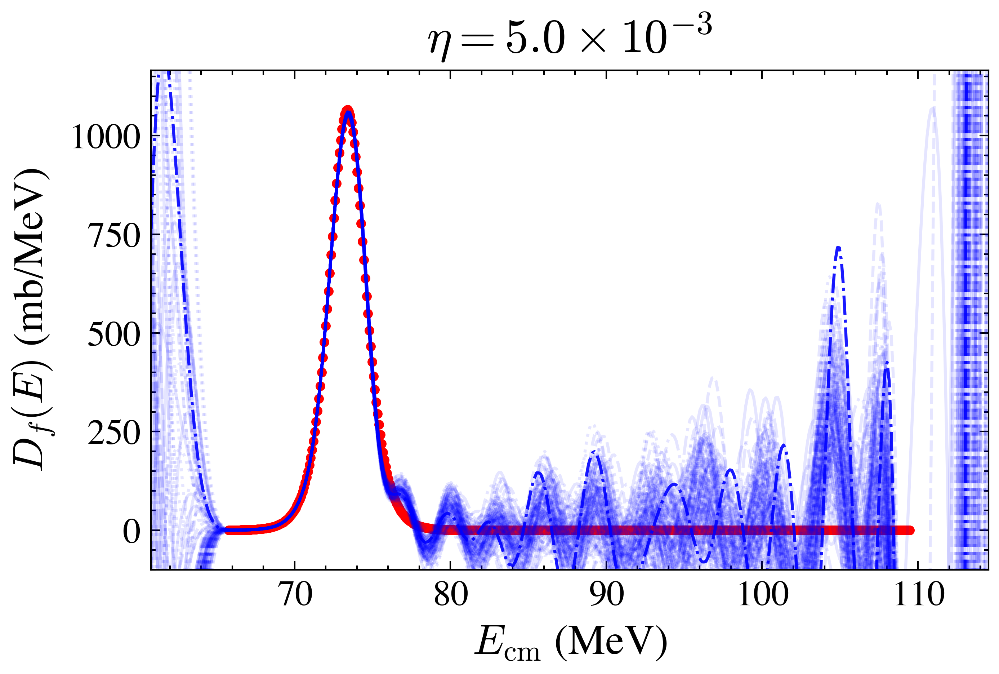

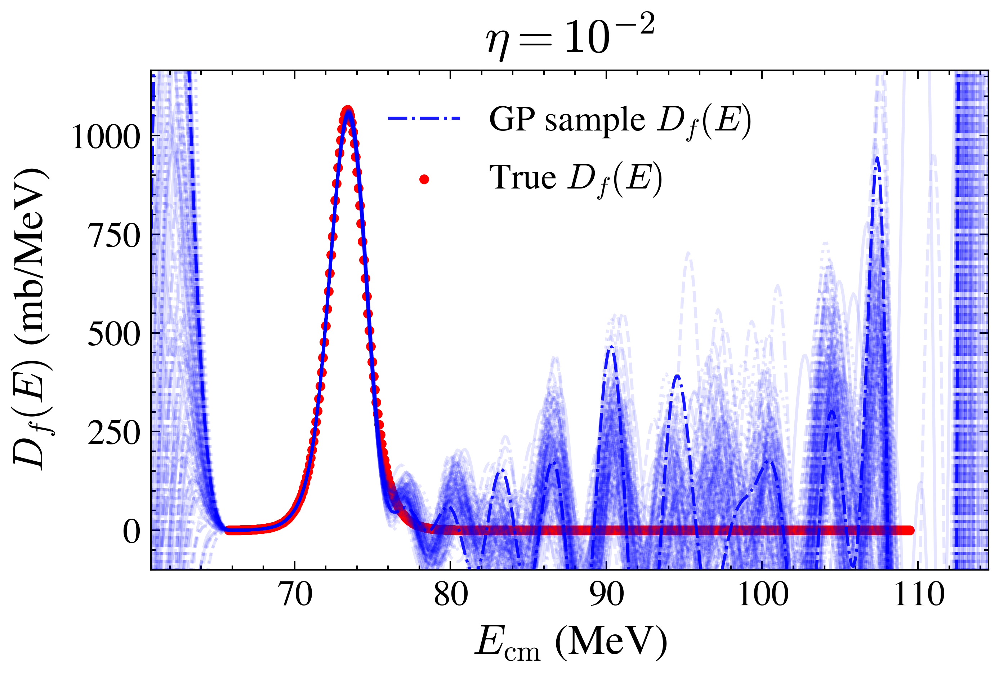

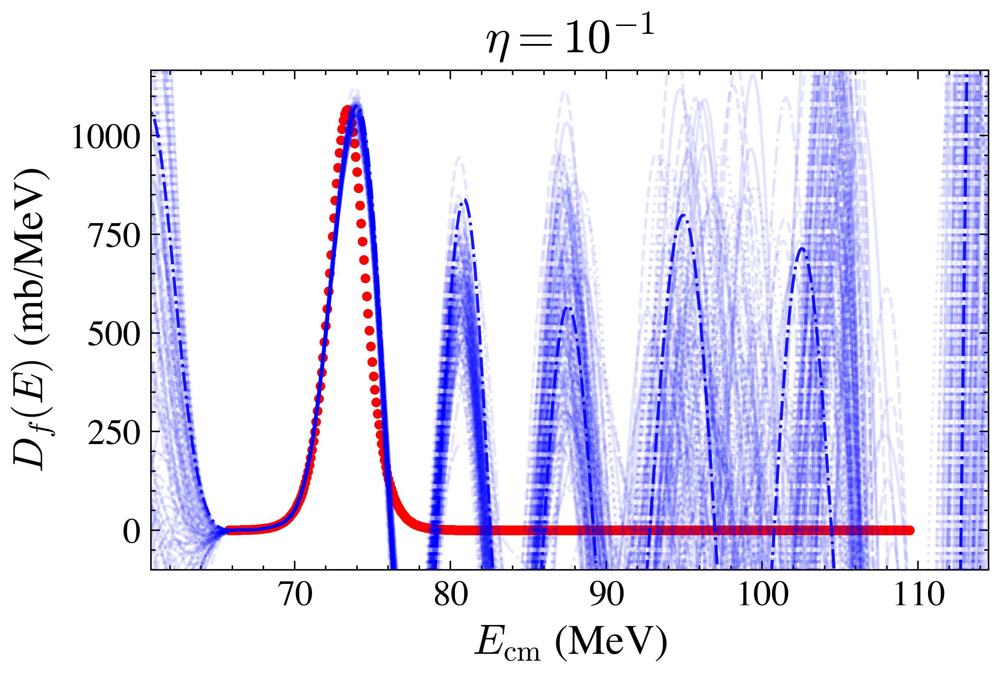

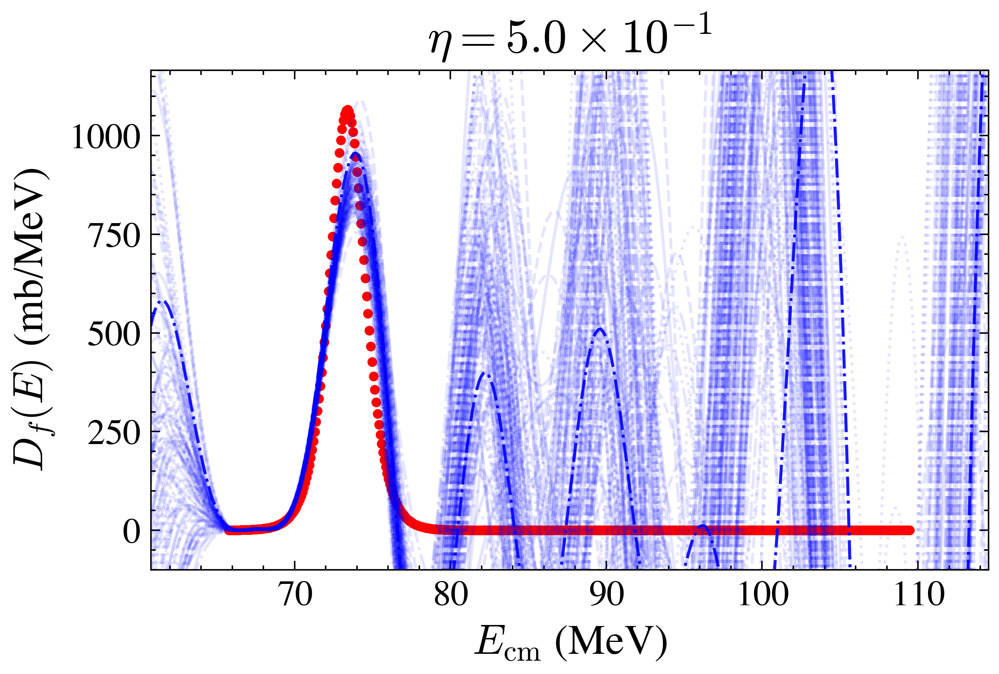

In [233]:
labeled = False
for i, data in results_noise.items():
    mu      = data['mu']
    std     = data['std']
    samples = data['samples']
    ratio =     data['ratio']
    tag     = f"{i}"
    var = (ratio*sigma_train)**2.0
    
    e = int(np.floor(np.log10(ratio)))
    # 2) get mantissa m so that η = m × 10^e
    m = ratio / 10**e

    # 3) build title
    if np.isclose(m, 1.0):
        # pure power of ten
        title = rf"$\eta = 10^{{{e}}}$"
    else:
        # include mantissa
        title = rf"$\eta = {m:.1f}\times 10^{{{e}}}$"
    # 1) σ(E) fit + 95% CI
    fig, ax = plt.subplots(figsize=(5,3))
    ax.plot(E_eval, mu, lw=2, label="GP mean")
    ax.plot(
        E_eval,
        sigma(E_eval, E0_opt, R0_opt, hbarw_opt),
        linestyle="--", color="C1", label="Wong"
    )
    ax.fill_between(
        E_eval,
        mu - 1.96 * std,
        mu + 1.96 * std,
        alpha=0.3,
        label="95% CI"
    )
    ax.scatter(
        E_train,
        sigma_train,
        s=10,               # area in points^2; adjust smaller/larger as you like
        color='red',
        label="Training pts",
        zorder=5
    )
    ax.set_title(title, fontsize=16)
    ax.set_xlabel(r'$E_{\mathrm{cm}}$ (MeV)', fontsize=14)
    ax.set_ylabel(r'$\sigma(E)$', fontsize=14)
    ax.set_xlim(E_eval[0], E_eval[-1])
    if i ==1: 
        ax.legend(fontsize=12)
    ax.tick_params(labelsize=12)
    fig.savefig(f'plots/gp_sigma_var_{tag}_noise.png', dpi=300)
    plt.close(fig)

    # 2) Barrier distributions
    fig, ax = plt.subplots(figsize=(5,3))
    for j in range(samples.shape[1]):
        style = dict(alpha=0.1, color='b')
        if j == samples.shape[1] - 1:
            style.update(alpha=0.9, label=r"GP sample $D_f(E)$")
        ax.plot(E_eval, barrier_dist(E_eval, samples[:, j], acc=4), **style)

    ax.scatter(
        E_train[::2],
        true_d[::2],
        s=5,
        color='r',
        label=r"True $D_f(E)$"
    )
    ax.set_title(title, fontsize=16)
    ax.set_xlabel(r'$E_{\mathrm{cm}}$ (MeV)', fontsize=14)
    ax.set_ylabel(r'$D_f(E)$ (mb/MeV)', fontsize=14)
    ax.set_xlim(E_train[0]-5, E_train[-1]+5)
    ax.set_ylim(true_d.min()-100, true_d.max()+100)
    if i==1: 
        ax.legend(fontsize=12)
        labeled = True
    ax.tick_params(labelsize=12)
    fig.savefig(f'plots/gp_barrier_var_{tag}_noise.png', dpi=300)
    plt.show()
    plt.close(fig)

### Effect of Resolution at noise ratio 10^-1

In [234]:
# ┌─ Cell 1: TRAIN & SAMPLE ────────────────────────────────────────────────────

import numpy as np

# assume these already exist in your namespace:
# E_train, sigma_train, sigma_var, E_dist, n_samples, train_gp, barrier_dist, sigma, E0_opt, R0_opt, hbarw_opt


factors = [5,10,20,40]
barrier_results = {}

for f in factors:
    # 1) coarsen the training set by factor f
    stop = np.argmin(np.abs(E_fine-80.0))
    E_tr   = E_fine[:stop:f]
    E_dist = np.arange(E_tr[0]-5,E_tr[-1]+5, 0.2)
    y_tr   = sigma_mean[:stop:f]
    var_tr = (0.1*y_tr)**2#sigma_var[:stop:f]
    y_tr_noisy = y_tr + rng.normal(0,np.sqrt(var_tr))
    # 2) train GP on the coarsened data
    gp = train_gp(E_tr, y_tr_noisy, var_tr)

    # 3) sample from the GP for barrier distributions
    samples = gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)

    barrier_results[f] = {
        "E_tr": E_tr,
        "samples": samples
    }

7087.42276100682


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


7794.551925309327


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


7554.542455179
9413.635625837902


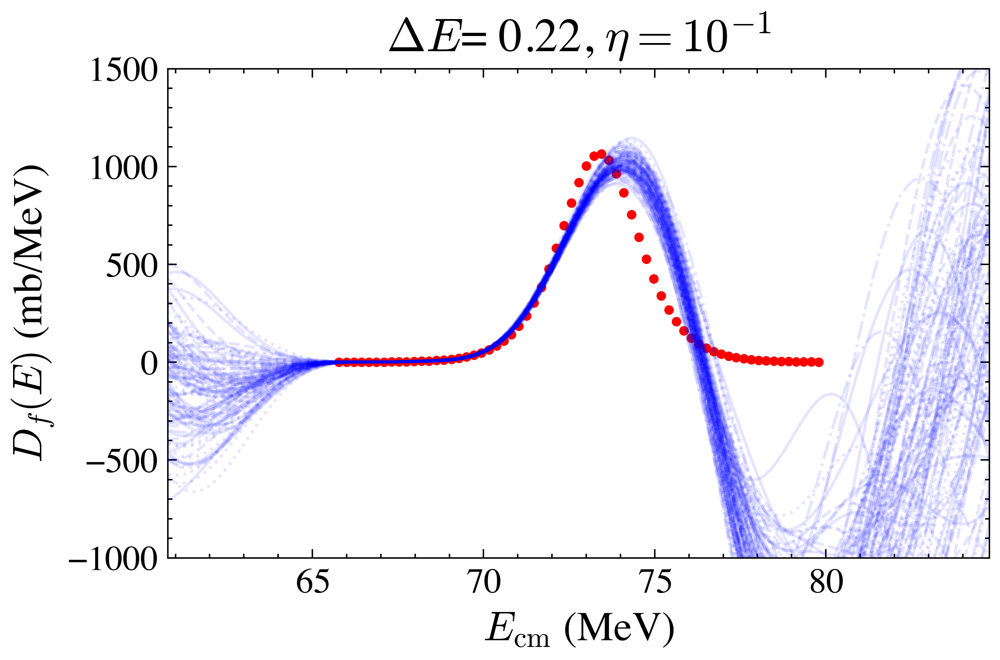

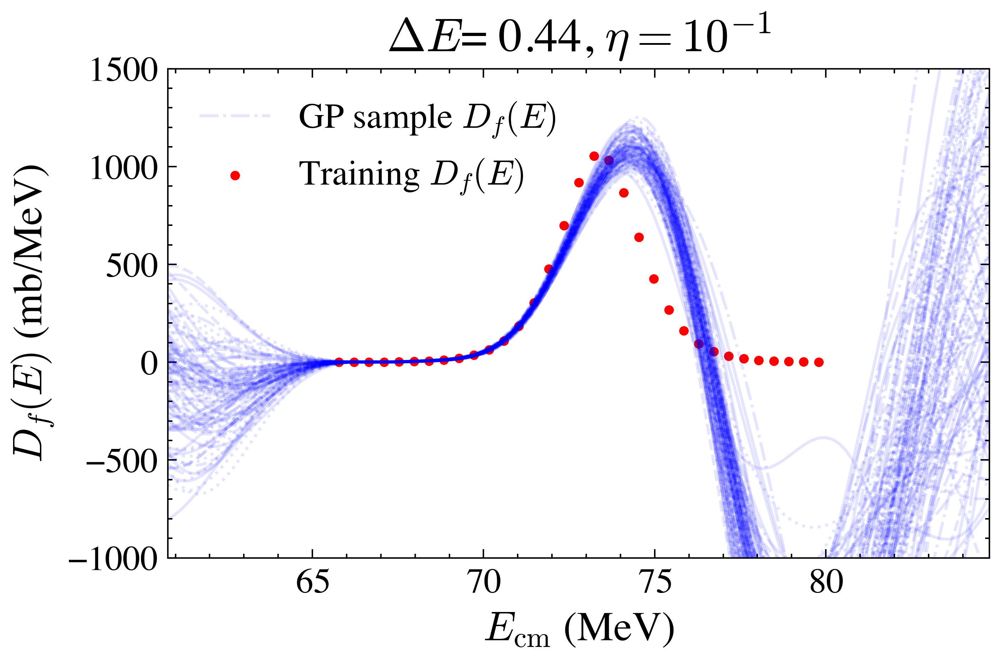

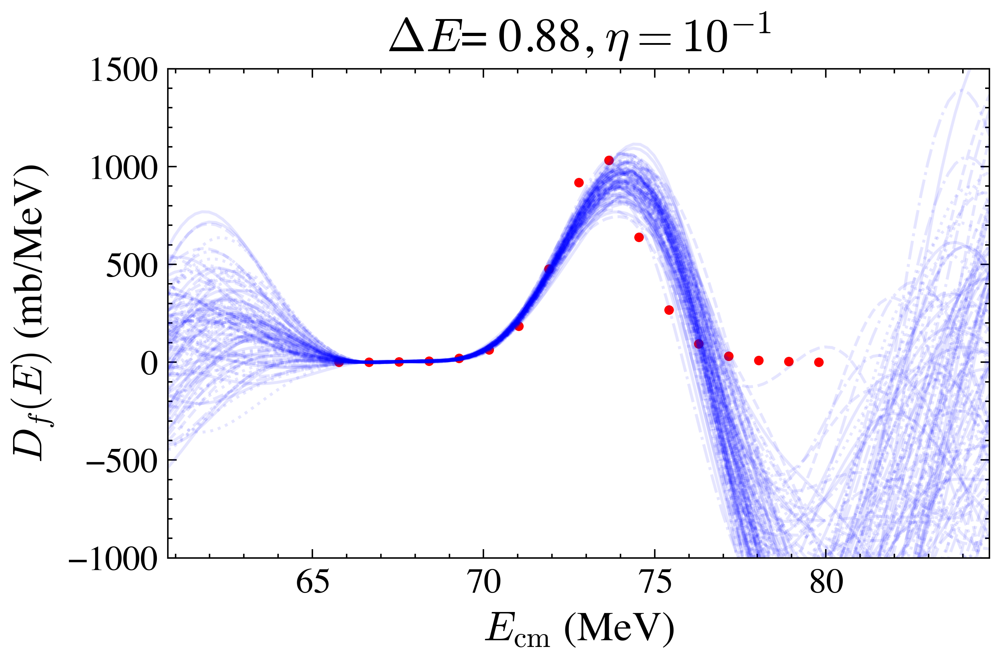

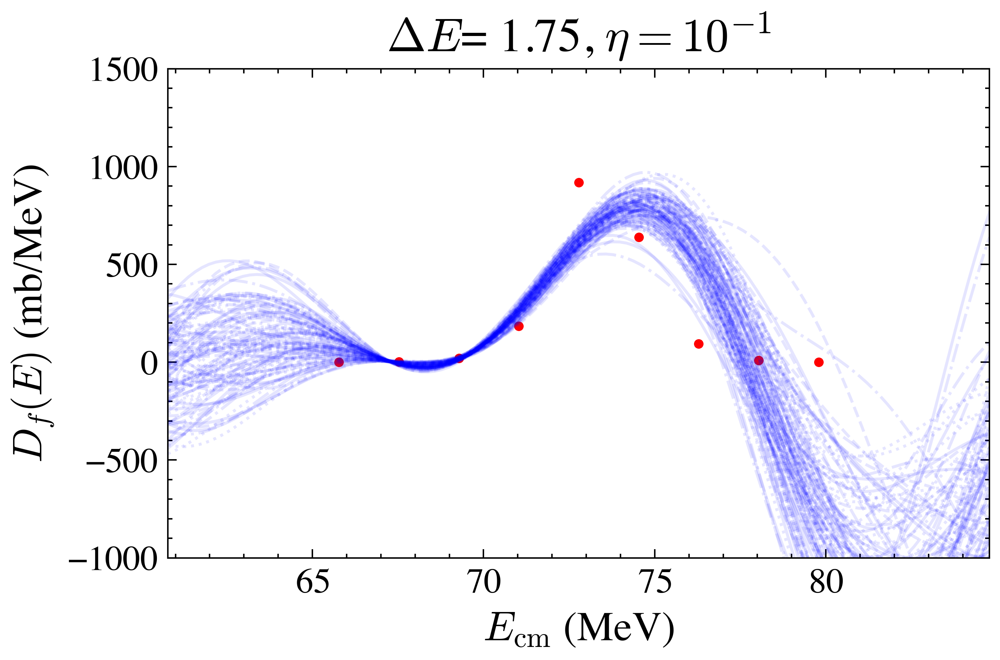

In [235]:
# ┌─ Cell 2: PLOT & SAVE ONLY BARRIER DISTRIBUTIONS ───────────────────────────

import matplotlib.pyplot as plt

d_fine = barrier_dist(
    E_train,
    sigma(E_train, E0_opt, R0_opt, hbarw_opt),
    acc=4
)


for f, data in barrier_results.items():
    E_tr    = data["E_tr"]
    samples = data["samples"]
    dE = E_tr[1] - E_tr[0]
    fig, ax = plt.subplots(figsize=(5,3))
    for j in range(samples.shape[1]):
        E_dist = np.arange(E_tr[0]-5,E_tr[-1]+5, 0.2)
        ax.plot(E_dist,
                barrier_dist(E_dist, samples[:, j], acc=4),
                color='b',
                alpha=0.1,# if j < samples.shape[1]-1 else 0.9,
                label=(r"GP sample $D_f(E)$" if j==samples.shape[1]-1 else None))

    # ground truth
    idx = np.searchsorted(E_train, E_tr)
    true_d = d_fine[idx]

    ax.scatter(E_tr, true_d, color='r', s=5, label=r"Training $D_f(E)$")

    ax.set_title(rf"$\Delta E$= {dE:.2f}, $\eta= 10^{{-1}}$", fontsize=16)
    ax.set_xlabel(r'$E_{\mathrm{cm}}$ (MeV)', fontsize=14)
    ax.set_ylabel(r'$D_f(E)$ (mb/MeV)', fontsize=14)
    ax.tick_params(labelsize=12)
    if f == 10:
        ax.legend(fontsize=12)
    ax.set_xlim(E_dist[0], E_dist[-1])
    ax.set_ylim(-1000, 1500)

    fig.savefig(f'plots/barrier_coarse_{f}_e-1.png', dpi=300)
    plt.show()
    plt.close(fig)


### Effect of Resolution at noise ratio $10^{-2}$

In [242]:
# ┌─ Cell 1: TRAIN & SAMPLE ────────────────────────────────────────────────────

import numpy as np

# assume these already exist in your namespace:
# E_train, sigma_train, sigma_var, E_dist, n_samples, train_gp, barrier_dist, sigma, E0_opt, R0_opt, hbarw_opt


factors = [5,10,20,40]
barrier_results_2 = {}

for f in factors:
    # 1) coarsen the training set by factor f
    stop = np.argmin(np.abs(E_fine-80.0))
    E_tr   = E_fine[:stop:f]
    E_dist = np.arange(E_tr[0]-5,E_tr[-1]+5, 0.2)
    y_tr   = sigma_mean[:stop:f]
    var_tr = (0.01*y_tr)**2#sigma_var[:stop:f]

    y_tr_noisy = y_tr + rng.normal(0,np.sqrt(var_tr))
    # 2) train GP on the coarsened data
    gp = train_gp(E_tr, y_tr_noisy, var_tr)

    # 3) sample from the GP for barrier distributions
    samples = gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)

    barrier_results_2[f] = {
        "E_tr": E_tr,
        "samples": samples
    }

7266.62321742413


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


7315.297145894691


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


7874.615113512351


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


8970.521610335007


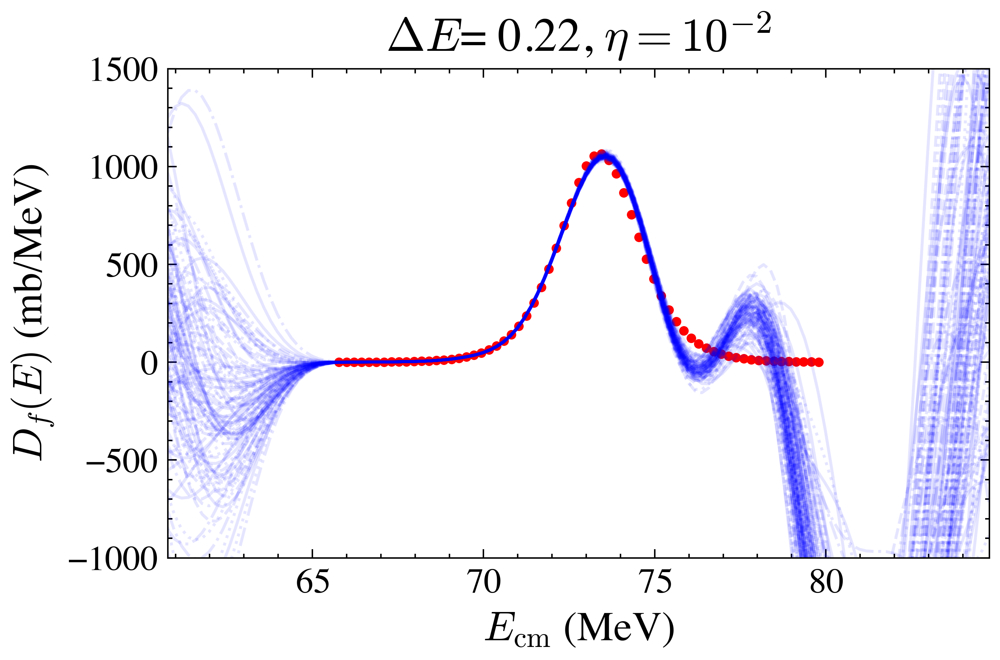

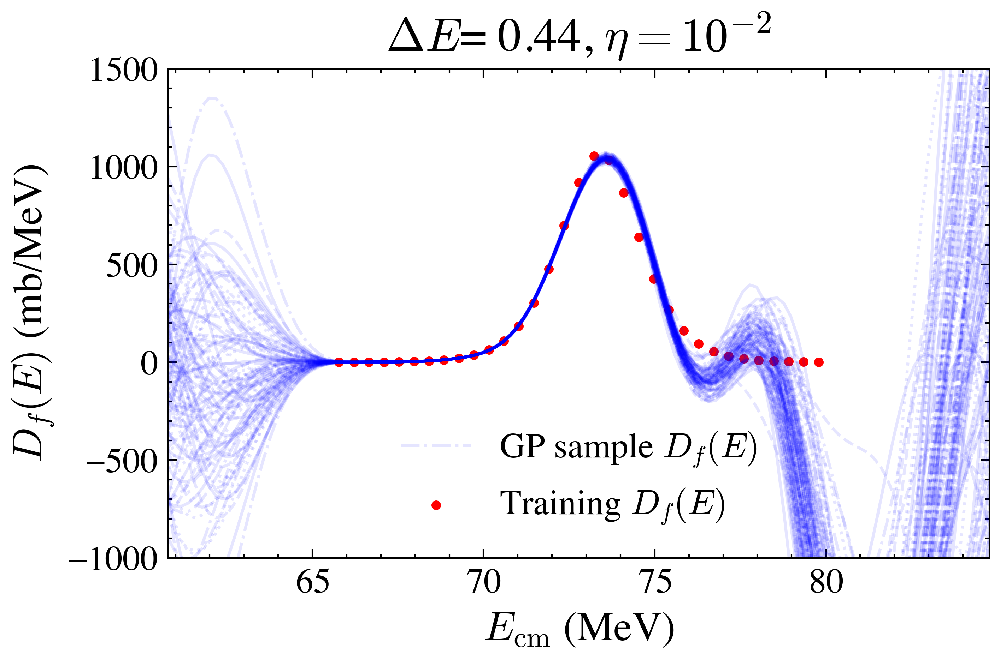

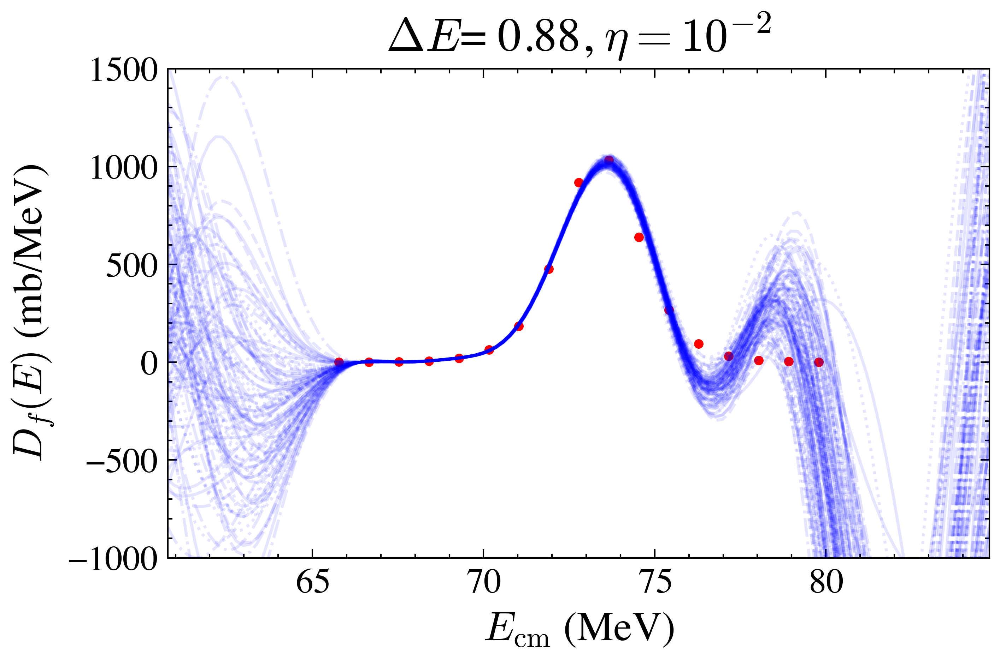

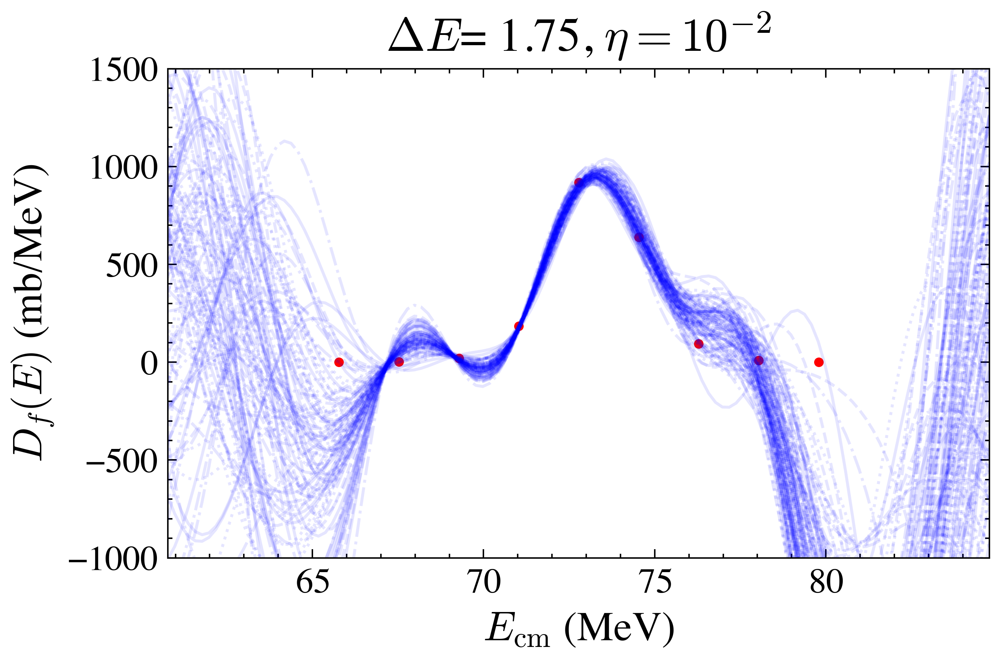

In [243]:
# ┌─ Cell 2: PLOT & SAVE ONLY BARRIER DISTRIBUTIONS ───────────────────────────

import matplotlib.pyplot as plt

d_fine = barrier_dist(
    E_train,
    sigma(E_train, E0_opt, R0_opt, hbarw_opt),
    acc=4
)


for f, data in barrier_results_2.items():
    E_tr    = data["E_tr"]
    samples = data["samples"]
    dE = E_tr[1] - E_tr[0]
    fig, ax = plt.subplots(figsize=(5,3))
    for j in range(samples.shape[1]):
        E_dist = np.arange(E_tr[0]-5,E_tr[-1]+5, 0.2)
        ax.plot(E_dist,
                barrier_dist(E_dist, samples[:, j], acc=4),
                color='b',
                alpha=0.1,# if j < samples.shape[1]-1 else 0.9,
                label=(r"GP sample $D_f(E)$" if j==samples.shape[1]-1 else None))

    # ground truth
    idx = np.searchsorted(E_train, E_tr)
    true_d = d_fine[idx]

    ax.scatter(E_tr, true_d, color='r', s=5, label=r"Training $D_f(E)$")

    ax.set_title(rf"$\Delta E$= {dE:.2f}, $\eta= 10^{{-2}}$", fontsize=16)
    ax.set_xlabel(r'$E_{\mathrm{cm}}$ (MeV)', fontsize=14)
    ax.set_ylabel(r'$D_f(E)$ (mb/MeV)', fontsize=14)
    ax.tick_params(labelsize=12)
    if f == 10:
        ax.legend(fontsize=12)
    ax.set_xlim(E_dist[0], E_dist[-1])
    ax.set_ylim(-1000, 1500)

    fig.savefig(f'plots/barrier_coarse_{f}_e-2.png', dpi=300)
    plt.show()
    plt.close(fig)

### Finally, let's see how irregularity of data affects things. 

### average spacing of 0.5 MeV

In [244]:
import numpy as np

# assume in namespace:
# E_fine, sigma_mean, n_samples, train_gp

cv_values = [0.0, 0.25, 0.5, 0.75]
mean_spacing = 0.5 # 0.5   # MeV
barrier_results_cv = {}

# find upper limit in E_fine (closest to 80 MeV)
stop_idx = np.argmin(np.abs(E_fine - 80.0))
E_min, E_max = E_fine[0], E_fine[stop_idx]

# evaluation grid (unchanged)
E_dist = np.arange(E_min - 5, E_max + 5, 0.2)

for cv in cv_values:
    std_sp = mean_spacing * cv
    # estimate number of points needed
    N = int((E_max - E_min) / mean_spacing) + 5

    # 1) draw irregular spacings and build E_tr
    dE_sim = np.random.normal(loc=mean_spacing, scale=std_sp, size=N)
    dE_sim = np.clip(dE_sim, 1e-3, None)      # enforce positive steps
    E_tr = E_min + np.cumsum(dE_sim)
    E_tr = E_tr[E_tr <= E_max]

    # 2) get y_tr & var_tr by interpolation of your fine σ-grid
    y_tr   = np.interp(E_tr, E_fine[:stop_idx], sigma_mean[:stop_idx])
    var_tr = (0.01 * y_tr)**2
    y_tr_noisy = y_tr + rng.normal(0,np.sqrt(var_tr))

    # 3) train & sample
    gp = train_gp(E_tr, y_tr_noisy, var_tr)
    samples = gp.sample_y(E_dist.reshape(-1,1), n_samples=n_samples)

    barrier_results_cv[cv] = {
        "E_tr":    E_tr,
        "y_tr":    y_tr,
        "var_tr":  var_tr,
        "samples": samples
    }

7524.122925019156


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


7572.251406424486


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


7371.521679982836


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


1944.5643518038926


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


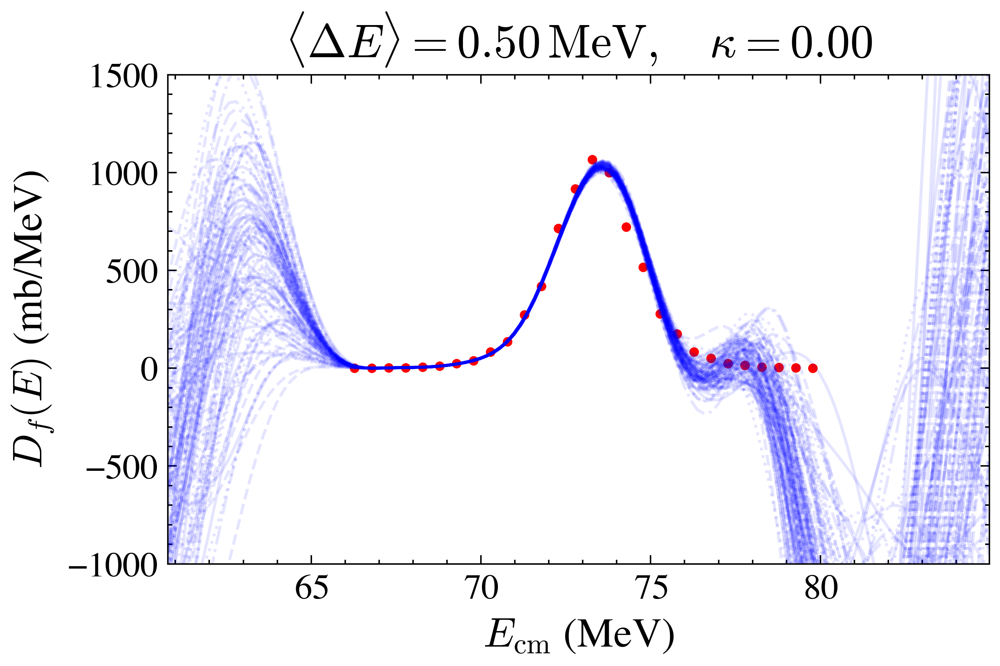

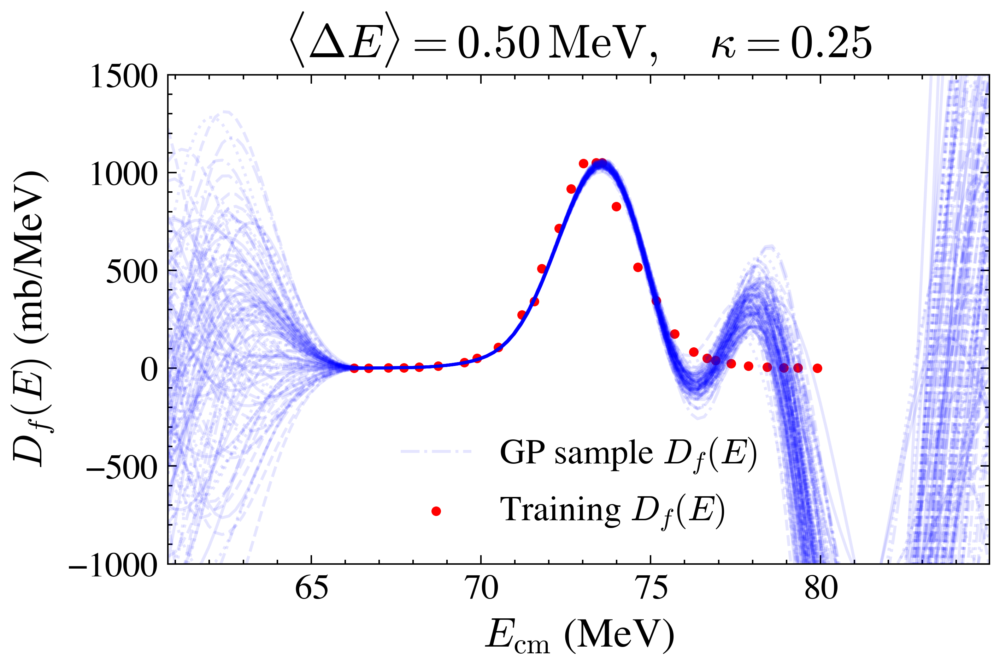

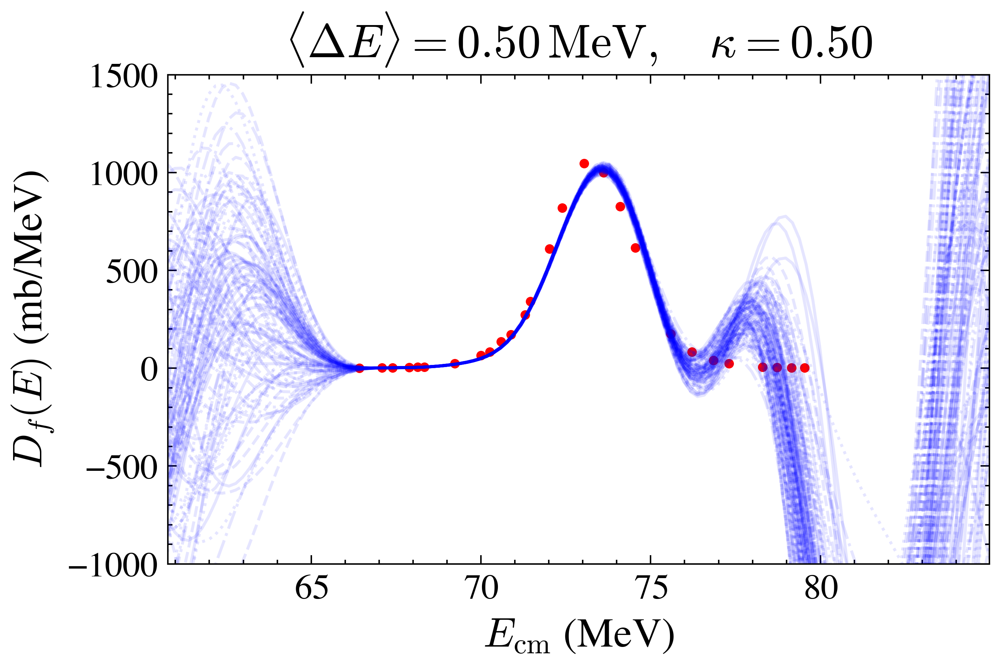

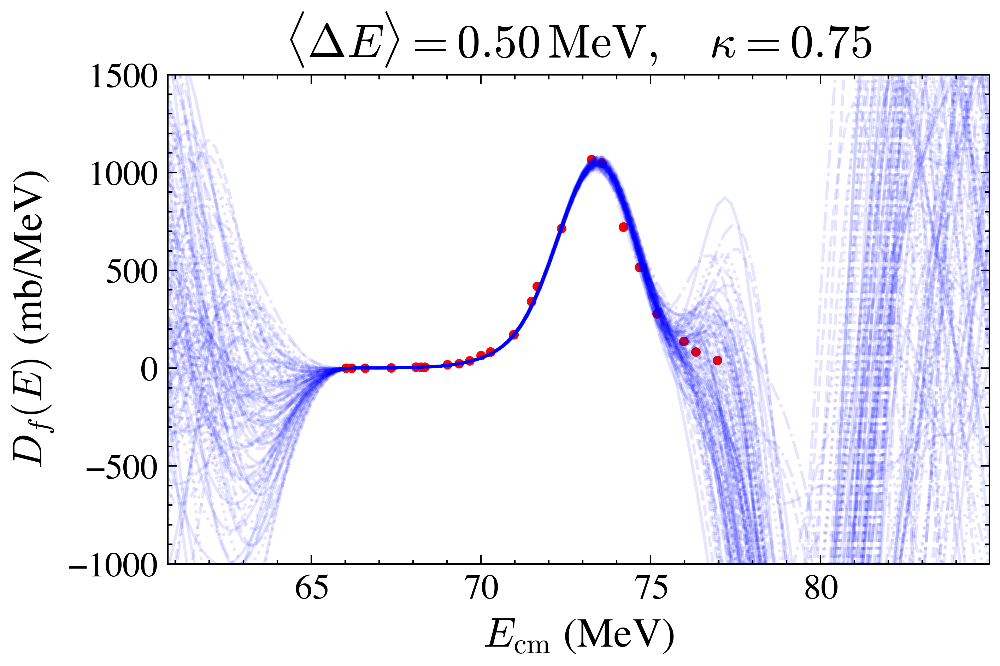

In [245]:
import matplotlib.pyplot as plt

# --- precompute fine-barrier on E_dist ---
d_fine_dist = barrier_dist(
    E_dist,
    sigma(E_dist, E0_opt, R0_opt, hbarw_opt),
    acc=4
)

for cv, data in barrier_results_cv.items():
    E_tr    = data["E_tr"]
    samples = data["samples"]

    # mean spacing for title
    dE_mean = np.mean(np.diff(E_tr))

    fig, ax = plt.subplots(figsize=(5,3))

    # plot GP samples
    for j in range(samples.shape[1]):
        ax.plot(
            E_dist,
            barrier_dist(E_dist, samples[:, j], acc=4),
            color='b',
            alpha=0.1,
            label=(r"GP sample $D_f(E)$" if j == samples.shape[1]-1 else None)
        )

    # ground truth at the E_tr points
    idx    = np.searchsorted(E_dist, E_tr)
    true_d = d_fine_dist[idx]
    ax.scatter(
        E_tr,
        true_d,
        color='r',
        s=5,
        label=r"Training $D_f(E)$"
    )

    ax.set_title(
        rf"$\langle\Delta E\rangle = {mean_spacing:.2f}\,\mathrm{{MeV}},\quad"
        rf"\kappa = {cv:.2f}$",
        fontsize=16
    )
    ax.set_xlabel(r'$E_{\mathrm{cm}}$ (MeV)', fontsize=14)
    ax.set_ylabel(r'$D_f(E)$ (mb/MeV)',      fontsize=14)
    ax.tick_params(labelsize=12)
    ax.set_xlim(E_dist[0], E_dist[-1])
    ax.set_ylim(-1000, 1500)

    # legend only once
    if cv ==0.25: 
        ax.legend(fontsize=12)

    # save & close
    fig.savefig(f'plots/barrier_cv_{cv:.2f}_0.5.png', dpi=300)
    plt.show()
    plt.close(fig)


In [246]:
import numpy as np

# assume in namespace:
# E_fine, sigma_mean, n_samples, train_gp

cv_values = [0.0, 0.25, 0.5, 0.75]
mean_spacing = 1.0 # 0.5   # MeV
barrier_results_cv_2 = {}

# find upper limit in E_fine (closest to 80 MeV)
stop_idx = np.argmin(np.abs(E_fine - 80.0))
E_min, E_max = E_fine[0], E_fine[stop_idx]

# evaluation grid (unchanged)
E_dist = np.arange(E_min - 5, E_max + 5, 0.2)

for cv in cv_values:
    std_sp = mean_spacing * cv
    # estimate number of points needed
    N = int((E_max - E_min) / mean_spacing) + 5

    # 1) draw irregular spacings and build E_tr
    dE_sim = np.random.normal(loc=mean_spacing, scale=std_sp, size=N)
    dE_sim = np.clip(dE_sim, 1e-3, None)      # enforce positive steps
    E_tr = E_min + np.cumsum(dE_sim)
    E_tr = E_tr[E_tr <= E_max]

    # 2) get y_tr & var_tr by interpolation of your fine σ-grid
    y_tr   = np.interp(E_tr, E_fine[:stop_idx], sigma_mean[:stop_idx])
    var_tr = (0.01 * y_tr)**2
    y_tr_noisy = y_tr + rng.normal(0, np.sqrt(var_tr))

    # 3) train & sample
    gp = train_gp(E_tr, y_tr_noisy, var_tr)
    samples = gp.sample_y(E_dist.reshape(-1,1), n_samples=n_samples)

    barrier_results_cv_2[cv] = {
        "E_tr":    E_tr,
        "y_tr":    y_tr,
        "var_tr":  var_tr,
        "samples": samples
    }

8112.373955515461
7032.341707057452
6994.483540335066
4932.742227330251


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


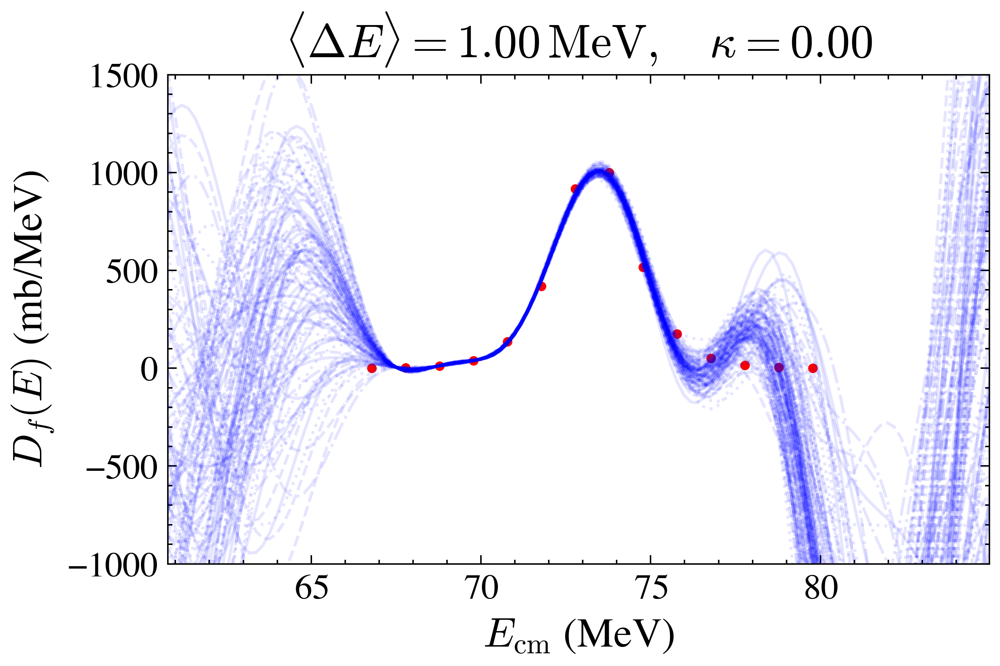

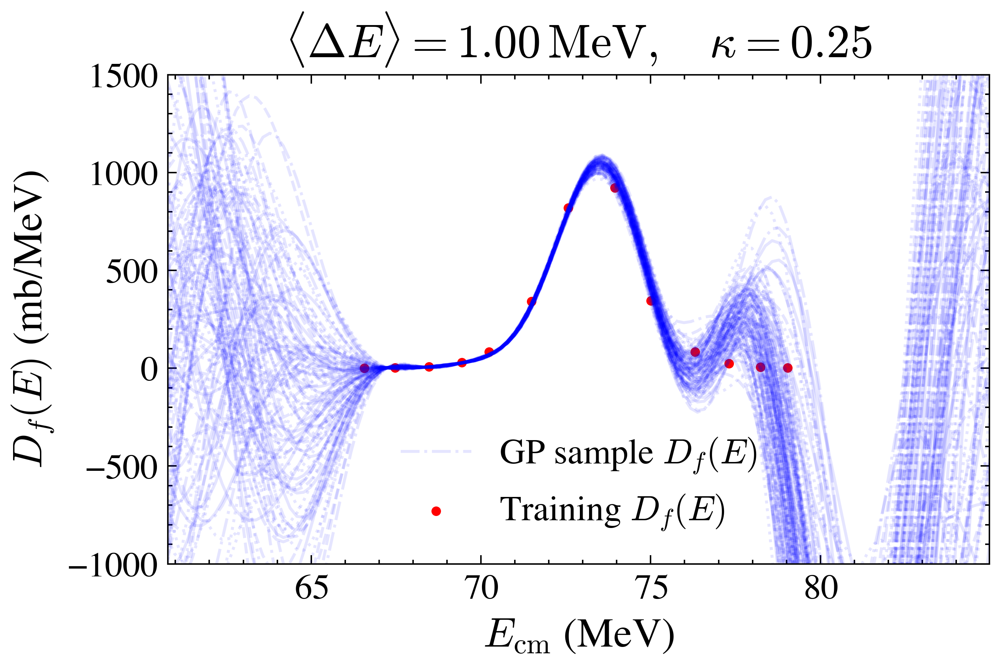

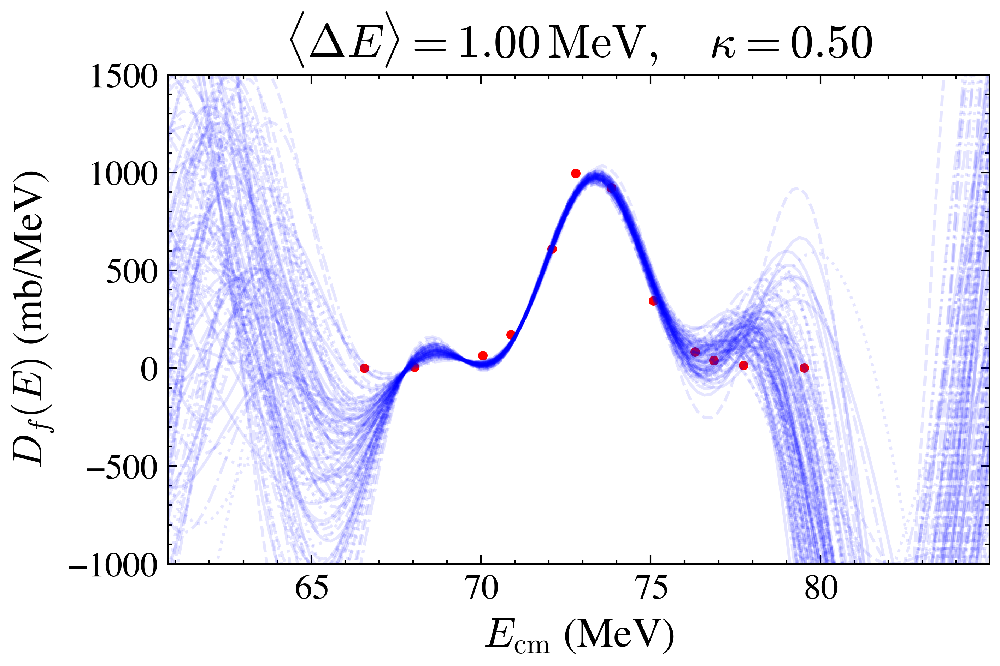

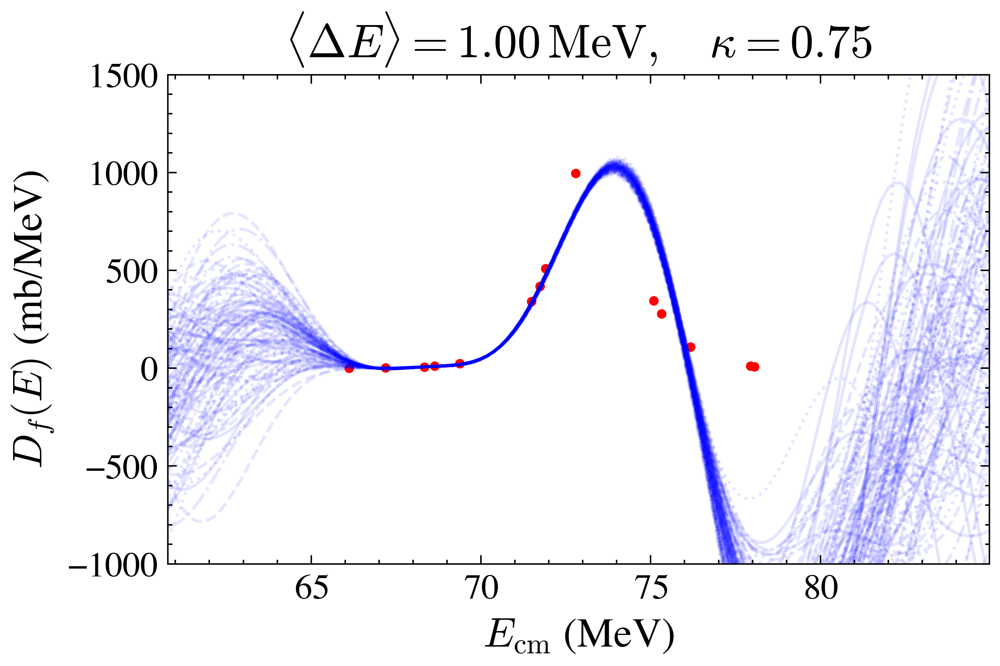

In [247]:
import matplotlib.pyplot as plt

# --- precompute fine-barrier on E_dist ---
d_fine_dist = barrier_dist(
    E_dist,
    sigma(E_dist, E0_opt, R0_opt, hbarw_opt),
    acc=4
)

for cv, data in barrier_results_cv_2.items():
    E_tr    = data["E_tr"]
    samples = data["samples"]

    # mean spacing for title
    dE_mean = np.mean(np.diff(E_tr))

    fig, ax = plt.subplots(figsize=(5,3))

    # plot GP samples
    for j in range(samples.shape[1]):
        ax.plot(
            E_dist,
            barrier_dist(E_dist, samples[:, j], acc=4),
            color='b',
            alpha=0.1,
            label=(r"GP sample $D_f(E)$" if j == samples.shape[1]-1 else None)
        )

    # ground truth at the E_tr points
    idx    = np.searchsorted(E_dist, E_tr)
    true_d = d_fine_dist[idx]
    ax.scatter(
        E_tr,
        true_d,
        color='r',
        s=5,
        label=r"Training $D_f(E)$"
    )
    ax.set_title(
        rf"$\langle\Delta E\rangle = {mean_spacing:.2f}\,\mathrm{{MeV}},\quad"
        rf"\kappa = {cv:.2f}$",
        fontsize=16
    )
    ax.set_xlabel(r'$E_{\mathrm{cm}}$ (MeV)', fontsize=14)
    ax.set_ylabel(r'$D_f(E)$ (mb/MeV)',      fontsize=14)
    ax.tick_params(labelsize=12)
    ax.set_xlim(E_dist[0], E_dist[-1])
    ax.set_ylim(-1000, 1500)

    # legend only once
    if cv==0.25: 
        ax.legend(fontsize=12)

    # save & close
    fig.savefig(f'plots/barrier_cv_{cv:.2f}_1.0.png', dpi=300)
    plt.show()
    plt.close(fig)

### Big Picture Conclusions: 

- The GP begins to miss the barrier when the estimated error to sigma ratio is between order of magnitudes 0.01 and 0.1. 
- In general, adding a White Noise kernel has little to no effect when included as the optimizer tries to minimize the noise level. 

- At characteristic resolutions of realistic experimental data, one can actually have very sparse data if the noise ratio is around $10^{-2}$

- We quantify irregularity of our data by the CV of the step sizes. Again, so long as noise ratio is low, one can use very irregular data and still capture the height and location of the barrier well. 